First five rows:
   age  sex   BP  cholestrol  heart disease
0   70    1  130         322              1
1   67    0  115         564              0
2   57    1  124         261              1
3   64    1  128         263              0
4   74    0  120         269              0

Dataset shape: (270, 5)

Missing values:
age              0
sex              0
BP               0
cholestrol       0
heart disease    0
dtype: int64

Class distribution:
heart disease
0    150
1    120
Name: count, dtype: int64

--- Gini Model ---
Accuracy: 0.6481481481481481
Precision: 0.5862068965517241
Recall: 0.7083333333333334
F1 Score: 0.6415094339622641
Tree Depth: 4
Number of Leaves: 12

--- Entropy Model ---
Accuracy: 0.6666666666666666
Precision: 0.65
Recall: 0.5416666666666666
F1 Score: 0.5909090909090909
Tree Depth: 4
Number of Leaves: 12


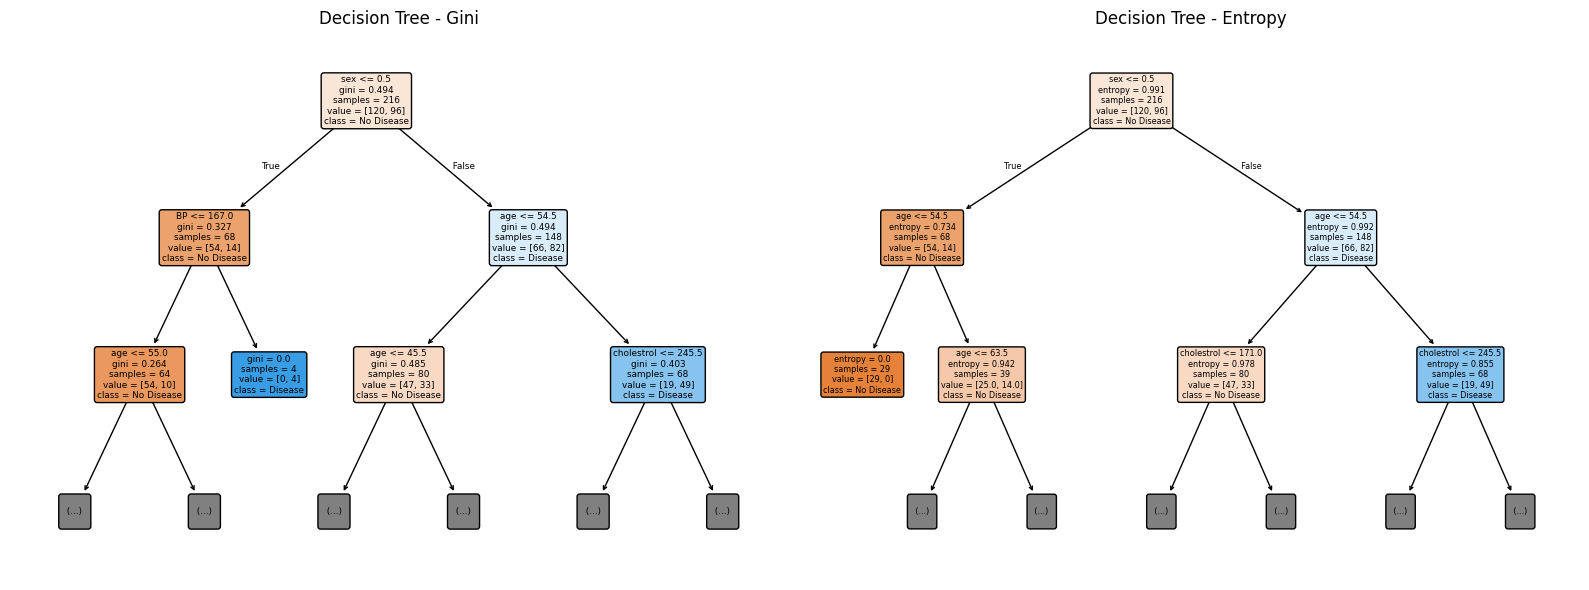


--- Optimized Model ---
Best Parameters: {'max_depth': 2, 'min_samples_leaf': 1}
Best Cross-Validation Accuracy: 0.694291754756871
Test Accuracy: 0.6296296296296297
Test Precision: 0.5909090909090909
Test Recall: 0.5416666666666666
Test F1 Score: 0.5652173913043478
Optimized Tree Depth: 2
Optimized Number of Leaves: 4


In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv("heart_v2.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["heart disease"].value_counts())

X = df.drop("heart disease", axis=1)
y = df["heart disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

gini_model = DecisionTreeClassifier(
    criterion="gini", max_depth=4, random_state=42
)

entropy_model = DecisionTreeClassifier(
    criterion="entropy", max_depth=4, random_state=42
)

gini_model.fit(X_train, y_train)
entropy_model.fit(X_train, y_train)

gini_pred = gini_model.predict(X_test)
entropy_pred = entropy_model.predict(X_test)

print("\n--- Gini Model ---")
print("Accuracy:", accuracy_score(y_test, gini_pred))
print("Precision:", precision_score(y_test, gini_pred, zero_division=0))
print("Recall:", recall_score(y_test, gini_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, gini_pred, zero_division=0))
print("Tree Depth:", gini_model.get_depth())
print("Number of Leaves:", gini_model.get_n_leaves())

print("\n--- Entropy Model ---")
print("Accuracy:", accuracy_score(y_test, entropy_pred))
print("Precision:", precision_score(y_test, entropy_pred, zero_division=0))
print("Recall:", recall_score(y_test, entropy_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, entropy_pred, zero_division=0))
print("Tree Depth:", entropy_model.get_depth())
print("Number of Leaves:", entropy_model.get_n_leaves())

plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plot_tree(
    gini_model, feature_names=X.columns,
    class_names=["No Disease", "Disease"],
    filled=True, rounded=True, max_depth=2
)
plt.title("Decision Tree - Gini")

plt.subplot(1, 2, 2)
plot_tree(
    entropy_model, feature_names=X.columns,
    class_names=["No Disease", "Disease"],
    filled=True, rounded=True, max_depth=2
)
plt.title("Decision Tree - Entropy")

plt.tight_layout()
plt.show()

parameters = {
    "max_depth": [2, 3, 4, 5, 6, None],
    "min_samples_leaf": [1, 2, 5, 10]
}

grid = GridSearchCV(
    DecisionTreeClassifier(criterion="gini", random_state=42),
    parameters, cv=5, scoring="accuracy"
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)

print("\n--- Optimized Model ---")
print("Best Parameters:", grid.best_params_)
print("Best Cross-Validation Accuracy:", grid.best_score_)
print("Test Accuracy:", accuracy_score(y_test, best_pred))
print("Test Precision:", precision_score(y_test, best_pred, zero_division=0))
print("Test Recall:", recall_score(y_test, best_pred, zero_division=0))
print("Test F1 Score:", f1_score(y_test, best_pred, zero_division=0))
print("Optimized Tree Depth:", best_model.get_depth())
print("Optimized Number of Leaves:", best_model.get_n_leaves())
